In [5]:
# Student Mark Prediction
# Import the all module as per need
# Load the Dataset
# 5 Basic Checks
# Perform EDA & Data Cleaning
# Visualize
# Prepare the data
# Fill the missing with descriptive statistics(mean,median,mode)
# Train the model with random forest
# evaluate the matrix(mae)
# new data


## We must check with 3 model such as :- RandomForestRegressor,LinearRegression,xgboost

##Output(RandomForestRegressor is the best Model for this Dataset which gives the best accuracy {MAE=5.5})

In [6]:
#Import the all module as per need

import pandas as pd

In [7]:
# Load the Dataset

df = pd.read_csv("/content/student_performance_messy.csv")
df

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
0,S089,Nisha,5.2,81.0,33.0,6.9,61.0
1,S073,Rahul,5.4,100.0,63.0,7.5,86.0
2,S115,Pooja,4.5,100.0,69.0,6.7,84.0
3,S159,Aarav,5.3,84.0,69.0,5.5,71.0
4,S164,priya,1.8,85.0,78.0,7.1,74.0
...,...,...,...,...,...,...,...
200,S018,NaN,NaN,92.0,69.0,6.4,76.0
201,S099,Aditya,4.5,99.0,66.0,6.0,86.0
202,S067,Riya,4.5,71.0,66.0,6.2,78.0
203,S127,Meera,1.5,100.0,62.0,6.5,58.0


In [8]:
# 5 Basic Checks
df.head(5)

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
0,S089,Nisha,5.2,81.0,33.0,6.9,61.0
1,S073,Rahul,5.4,100.0,63.0,7.5,86.0
2,S115,Pooja,4.5,100.0,69.0,6.7,84.0
3,S159,Aarav,5.3,84.0,69.0,5.5,71.0
4,S164,priya,1.8,85.0,78.0,7.1,74.0


In [9]:
df.tail()

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
200,S018,NaN,NaN,92.0,69.0,6.4,76.0
201,S099,Aditya,4.5,99.0,66.0,6.0,86.0
202,S067,Riya,4.5,71.0,66.0,6.2,78.0
203,S127,Meera,1.5,100.0,62.0,6.5,58.0
204,S110,Kabir,3.1,88.0,61.0,7.4,66.0


In [10]:
df.shape

# 205 num of Rows & 7 num of columns

(205, 7)

In [11]:
df.info()

#student name contain 4 Null values , study_hour contain 12 null,attendane_percent contain 11 null,prev_score contain 10 null,sleep_hr contain 12 null,exam_score contain 8 null

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          205 non-null    object 
 1   student_name        201 non-null    object 
 2   study_hours         193 non-null    object 
 3   attendance_percent  194 non-null    object 
 4   previous_score      195 non-null    object 
 5   sleep_hours         193 non-null    float64
 6   exam_score          197 non-null    float64
dtypes: float64(2), object(5)
memory usage: 11.3+ KB


In [12]:
df.describe()

,sleep_hours,exam_score
count,193.000000,197.000000
mean,7.023834,75.431472
std,1.297494,12.013242
min,-2.000000,51.000000
25%,6.300000,68.000000
50%,7.100000,75.000000
75%,7.800000,83.000000
max,10.000000,130.000000


In [13]:
# Summery
'''
Dataset contain Null Values
Dataset Contain wrong DataType
Not need the student Id & Name for Mark Prediction that's Why they are not need

'''

"\nDataset contain Null Values\nDataset Contain wrong DataType\nNot need the student Id & Name for Mark Prediction that's Why they are not need\n\n"

In [14]:
# Perform EDA & Data Cleaning

# Checks how much MissingValues individual Columns
df.isnull().sum()


,0
student_id,0
student_name,4
study_hours,12
attendance_percent,11
previous_score,10
sleep_hours,12
exam_score,8


In [15]:
# Checks how much MissingValues Total

df.isnull().sum().sum()

np.int64(57)

In [16]:
#Checks how much Duplicate Values

df.duplicated().sum()

np.int64(5)

In [17]:
print(df.duplicated())

0      False
1      False
2      False
3      False
4      False
       ...  
200    False
201    False
202     True
203    False
204    False
Length: 205, dtype: bool


In [18]:
# Except Sleep hours, & Exam Score all data are object type which means some text values are there

df['study_hours'].head(10)

# in the 6th num of raws it contain a text value with the decimal value

,study_hours
0,5.2
1,5.4
2,4.5
3,5.3
4,1.8
5,6.4
6,1.8 hrs
7,4.1
8,3.1
9,1.9


In [19]:
# Similarly we can check the rest


df.loc[[6,25,28,107]]

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
6,S186,Arjun,1.8 hrs,75.0,70.0,8.9,65.0
25,S105,Yash,1.5,88.0,55 / 100,7.7,57.0
28,S072,Sana,2.7,81%,60.0,7.4,61.0
107,S172,Ishaan,3.5,eighty,NaN,6.3,74.0


In [20]:
# We found hrs in study_hours
# eighty,% in attendance_percent
# /,NaN in prev_score


In [21]:
# We need to remove 1st the duplicate values

df.drop_duplicates()

,student_id,student_name,study_hours,attendance_percent,previous_score,sleep_hours,exam_score
0,S089,Nisha,5.2,81.0,33.0,6.9,61.0
1,S073,Rahul,5.4,100.0,63.0,7.5,86.0
2,S115,Pooja,4.5,100.0,69.0,6.7,84.0
3,S159,Aarav,5.3,84.0,69.0,5.5,71.0
4,S164,priya,1.8,85.0,78.0,7.1,74.0
...,...,...,...,...,...,...,...
199,S084,Arjun,3.2,100.0,66.0,8.4,75.0
200,S018,NaN,NaN,92.0,69.0,6.4,76.0
201,S099,Aditya,4.5,99.0,66.0,6.0,86.0
203,S127,Meera,1.5,100.0,62.0,6.5,58.0


In [22]:
# so we remove 5 records which are duplicate in our Dataset

In [23]:
# We need to replace the unwanted symbols and make the columns as float type

#study_hours	attendance_percent	previous_score

cols = ["study_hours","attendance_percent","previous_score"]

df[cols] = df[cols].replace({" hrs":"","%":""," / 100":"","eighty":"80"}, regex=True).astype(float)

In [24]:
df[cols]

,study_hours,attendance_percent,previous_score
0,5.2,81.0,33.0
1,5.4,100.0,63.0
2,4.5,100.0,69.0
3,5.3,84.0,69.0
4,1.8,85.0,78.0
...,...,...,...
200,NaN,92.0,69.0
201,4.5,99.0,66.0
202,4.5,71.0,66.0
203,1.5,100.0,62.0


In [25]:
df['study_hours'].head(10)

,study_hours
0,5.2
1,5.4
2,4.5
3,5.3
4,1.8
5,6.4
6,1.8
7,4.1
8,3.1
9,1.9


In [26]:
limits = {"study_hours":24,
          "attendance_percent":100,
          "previous_score":100}



for col,top in limits.items():

  df.loc[df[col] > top, col] = None
df.loc[df.sleep_hours < 0 ,"sleep_hours"] = None
df = df[df.exam_score <= 100]

In [27]:
len(df)

195

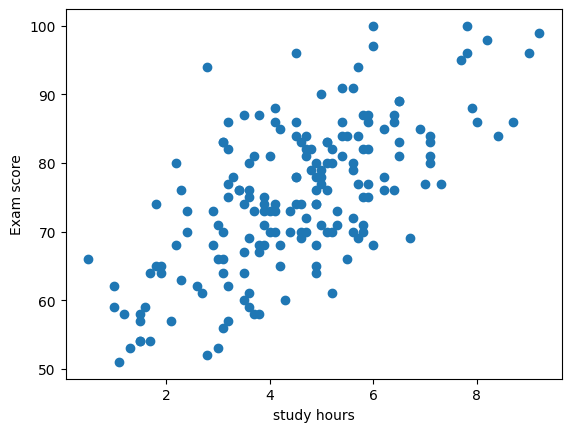

In [28]:
# Visualize

import matplotlib.pyplot as plt

plt.scatter(df.study_hours, df.exam_score)
plt.xlabel("study hours")
plt.ylabel("Exam score")
plt.show()

In [29]:
# Summery
# the above chart shows that if the study time is increase then mark also increase


In [31]:
df.columns

Index(['student_id', 'student_name', 'study_hours', 'attendance_percent',
       'previous_score', 'sleep_hours', 'exam_score'],
      dtype='object')

In [32]:
# Prepare the data

from sklearn.model_selection import train_test_split

# Input

X = df[['study_hours', 'attendance_percent',
       'previous_score', 'sleep_hours']]

Y = df["exam_score"]


X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state = 42)

In [33]:
#Fill the Naan Values by the help of Descriptive Statistics

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [34]:
# Train the model with random forest

from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(random_state=42)

model.fit(X_train,Y_train)


RandomForestRegressor(random_state=42)

In [35]:
# evaluate the matrix(mae)

from sklearn.metrics import mean_absolute_error
predictions = model.predict(X_test)
mae = mean_absolute_error(Y_test,predictions)
print(f"MAE :{round(mae,1)}")

MAE :5.5


In [36]:
# new data for predict  a student marks

new_student = pd.DataFrame({
    "study_hours":[6],
    "attendance_percent":[90],
    "previous_score":[75],
    "sleep_hours":[8]
})


score = model.predict(new_student)[0]
print(f"Predicted Score : {score}")

Predicted Score : 83.7


In [37]:
# new data for predict  a student marks

new_student = pd.DataFrame({
    "study_hours":[9],
    "attendance_percent":[20],
    "previous_score":[95],
    "sleep_hours":[4]
})


score = model.predict(new_student)[0]
print(f"Predicted Score : {score}")

Predicted Score : 91.87


In [38]:
# Train the model with random forest

from sklearn.linear_model import LinearRegression
model1 = LinearRegression()

model1.fit(X_train,Y_train)


LinearRegression()

In [39]:
# evaluate the matrix(mae)

from sklearn.metrics import mean_absolute_error
predictions = model1.predict(X_test)
mae = mean_absolute_error(Y_test,predictions)
print(f"MAE :{round(mae,1)}")

MAE :5.6


In [40]:
# new data for predict  a student marks

new_student = pd.DataFrame({
    "study_hours":[6],
    "attendance_percent":[90],
    "previous_score":[75],
    "sleep_hours":[8]
})


score = model1.predict(new_student)[0]
print(f"Predicted Score : {score}")

Predicted Score : 87.65893426399887


In [41]:
# new data for predict  a student marks

new_student = pd.DataFrame({
    "study_hours":[9],
    "attendance_percent":[20],
    "previous_score":[95],
    "sleep_hours":[4]
})


score = model1.predict(new_student)[0]
print(f"Predicted Score : {score}")

Predicted Score : 88.61946910970342


In [42]:
## Apply XGBoost Regression

import xgboost as xgb

In [43]:
model2 = xgb.XGBRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    random_state = 42
)

model2.fit(X_train,Y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [44]:
## Make Predictions
y_pred = model2.predict(X_test)

In [45]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [47]:
print("MAE:", mean_absolute_error(Y_test, y_pred))

print("MSE:", mean_squared_error(Y_test, y_pred))

print("RMSE:", mean_squared_error(Y_test, y_pred)**0.5)

print("R2 Score:", r2_score(Y_test, y_pred))

MAE: 5.840738345415164
MSE: 56.229702236845
RMSE: 7.498646693693803
R2 Score: 0.5191205209823828


In [48]:
# new data for predict  a student marks

new_student = pd.DataFrame({
    "study_hours":[9],
    "attendance_percent":[20],
    "previous_score":[95],
    "sleep_hours":[4]
})


score = model2.predict(new_student)[0]
print(f"Predicted Score : {score}")

Predicted Score : 89.07112884521484
